<a href="https://colab.research.google.com/github/mybenkhadda/GEMS---drivendata/blob/main/notebooks/colab/GEMS_MASTER_PIPELINE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GEMS 2.0 — Master pipeline

**One notebook for the whole workflow:** environment → data acquisition → native grid → DEM inventory → geological EDA repair → segment attributes → spatial splits → feature store → baselines → research experiments → discovery evaluation → ensembling → full inference → submission → reports.

Every stage **checks Drive first, reuses valid outputs, builds only what is missing, saves to Google Drive immediately and records provenance**. Re-running any cell after a disconnect resumes where it stopped.

### First time here? Run in three steps

1. **`PREPARE_DATA`** (recommended first run, CPU is enough): reuses the raw files and the saved spatial splits on Drive, rebuilds missing Phase‑1 EDA dependencies, creates the segment attributes and the baseline features, saves everything to Drive and **stops before any model training**.
2. **`BASELINES`** with `train_baselines=['G1']` (CPU): trains / verifies the G1 LightGBM, geographic CV + pseudo-discovery, OOF maps on Drive.
3. **`ADVANCED_RESEARCH`** (GPU runtime): research experiments.

Cells appear in dependency order (`pipe.graph()` is the source of truth):

```
bootstrap → raw_data → native_grid ─┬─ dem_inventory ─────────────────────────────→ dem_pilot (needs feature_store)
                                    ├─ geological_eda → segment_attributes ┄┄┐
                                    ├─ spatial_folds ────────────────────────┼─→ feature_store ─┬─→ dem_pilot
                                    └─ discovery_splits ─────────────────────┘                  │
   spatial_folds + discovery_splits (┄ feature_store, ┄ segment_attributes) ─→ baselines ─→ discovery_validation ─→ ensemble
   feature_store + baselines ─→ advanced_models (GPU)        feature_store ─→ full_inference (GPU) ─→ submission
   reports (always last)                                      ┄ = soft dependency: ordered first, never blocking
```

| decision | meaning |
|---|---|
| `SKIP_CACHED` | outputs exist, pass content checks, and were made under this configuration (or are pre-existing artifacts, adopted with provenance) |
| `BUILD` / `RESUME` | outputs missing / partial: built, or resumed from completed units and checkpoints |
| `INCOMPATIBLE` | outputs exist but differ from the configuration: **never overwritten**; changed protocols get a new versioned folder |
| `BLOCKED` | a prerequisite is missing: the message names the **root failure** and the recovery action |
| `DISABLED` | switched off in `CONFIG`, or a GPU stage on a CPU runtime |

**Failures:** with `failure_policy='interactive'` (default here) a failed critical stage prints the full traceback, the file and line, and the recovery action, then **stops “Run all”**. Completed artifacts are kept. `pipe.explain('<stage>')` shows it again later, also from an earlier session. With `'batch'`, independent stages continue and one grouped report lists each root failure with the stages it blocks.

**Safety:** GPU training, DEM tile downloads, full inference and submission export are off until enabled below. Nothing is ever deleted on Drive, nothing is uploaded to the competition, no URL or token is written to disk or to the Git remote. Pseudo-discovery scores are local-protocol numbers, never leaderboard scores.

Guide: `docs/MASTER_COLAB_GUIDE.md` · dependencies: `docs/PIPELINE_DEPENDENCIES.md` · recovery: `docs/ARTIFACT_RECOVERY.md`.

## 1. Configuration (control panel)

Edit, then run the cells top to bottom (or use the one-shot run in section 6). Keys are validated: a typo raises an error naming the closest valid key.

**Modes:** `SETUP_ONLY` (verify environment and existing data, no downloads) · **`PREPARE_DATA`** (recommended first run: data, EDA repair, segments, splits, features; no training) · `BASELINES` (+ restore / train the baselines listed in `train_baselines`, scoreboard) · `ADVANCED_RESEARCH` (+ GPU research experiments) · `FULL_PIPELINE` (every enabled stage) · `RESUME` (continue from saved state) · `SUBMISSION_ONLY` (promoted model → GeoTIFF; prerequisites validated, not rebuilt).

`ref` is either a **branch** (follows `origin/<branch>`, fast-forward only) or a **commit SHA / tag** (pinned, detached). The code cell prints which one was checked out.

In [1]:
CONFIG = {
    'repo': 'mybenkhadda/GEMS---drivendata',
    'ref': 'main',                                   # branch name, or a commit SHA / tag to pin the code
    'drive_root': '/content/drive/MyDrive/GEMS_2',
    'local_root': '/content/gems_work',

    'run_mode': 'PREPARE_DATA',                      # first run: PREPARE_DATA -> BASELINES -> ADVANCED_RESEARCH
    'failure_policy': 'interactive',                 # 'interactive': stop on a critical failure | 'batch': continue
    'download_missing': True,                        # only files absent / invalid on Drive AND locally
    'rebuild_missing': True,

    'run_eda': True,                                 # minimal Phase-1 rebuild if outputs/eda is missing (CPU)
    'run_baselines': True,                           # scan / verify baselines (cheap)
    'train_baselines': [],                           # BASELINES step: ['G1'] (CPU); later 'G3', 'B0_lineament'; GPU: 'CNN_A_dti', ...
    'run_advanced_features': True,                   # Phase-4 RS features used by the baselines
    'run_advanced_models': False,                    # GPU research experiments (opt-in)
    'advanced_experiments': ['b0_reference', 'b1_bg_weight', 'b2_nnpu_p010', 'c1_geometry_heads', 'e1_gsn_parity'],
    'run_dem_pilot': False,
    'run_scoreboard': True,
    'run_ensemble': True,
    'run_full_inference': False,                     # needs a PROMOTED model (manual decision)
    'run_submission': False,                         # writes GeoTIFFs; never uploads

    'use_gpu': True,                                 # GPU stages are DISABLED automatically when no CUDA GPU is attached
    'max_stage_minutes': 0,                          # e.g. 200 on free tier: clean, resumable stop
    'save_figures': True,
    'save_intermediate': True,
    'seed': 2026,
}

DEM_CONFIG = {
    'enabled': False,
    'mode': 'pilot',                                 # 'pilot' | 'inventory_only' (never the full collection)
    'download': False,                               # explicit approval, after reading the storage estimate
    'pilot_tiles': 24,                               # spatially balanced pilot (f1_dem_pilot.yaml)
    'max_tiles': 30,
    'max_gib': 15.0,
    'download_only_intersecting': True,
    'compute_morphology': True,                      # 1 m morphology before aggregation
    'aggregate_to_100m': True,
}
PRIVATE_REPO = False                                 # True only for a private fork: uses Colab Secret GITHUB_TOKEN per command

## 2–4. Google Drive, GitHub installation, package import

Idempotent: mounts Drive, clones (or updates) the repository at `CONFIG['ref']`, installs `gems-fault-discovery` in editable mode.

* The repository is public, so the clone is **token-free**. Older notebook versions put a token into the remote URL. This cell resets the remote to the plain URL.
* For a private fork set `PRIVATE_REPO = True`. The token from Colab *Secrets* (`GITHUB_TOKEN`) is passed to `git` through environment variables for that one command. It is never part of the URL, `.git/config`, the command line or any output.
* Git failures are **not** ignored. If a branch has diverged or the checkout has local edits, the cell stops with git's message.
* If the code changed after `gems_bench` was already imported in this kernel, the cell asks you to restart the session, so stale code is never used.
* PyTorch is **not** reinstalled (Colab's CUDA build is the right one).

In [2]:
import base64, os, subprocess, sys
from google.colab import drive
drive.mount('/content/drive')
CODE = '/content/GEMS'
REPO_URL = f"https://github.com/{CONFIG['repo']}.git"        # token-free remote (public repository)

def _git_env():
    """Private fork only: HTTP auth header via GIT_CONFIG_* env vars (git >= 2.31), never in URL / argv / config."""
    if not PRIVATE_REPO:
        return None
    from google.colab import userdata
    tok = userdata.get('GITHUB_TOKEN') or ''
    if not tok:
        raise RuntimeError('PRIVATE_REPO=True but the Colab Secret GITHUB_TOKEN is empty / not shared with this notebook')
    hdr = base64.b64encode(f'x-access-token:{tok}'.encode()).decode()
    return {**os.environ, 'GIT_CONFIG_COUNT': '1', 'GIT_CONFIG_KEY_0': 'http.https://github.com/.extraheader',
            'GIT_CONFIG_VALUE_0': f'AUTHORIZATION: basic {hdr}'}

def git(*args, auth=False, check=True):
    r = subprocess.run(['git', *args], capture_output=True, text=True, env=_git_env() if auth else None)
    if check and r.returncode != 0:                              # never silently ignored
        raise RuntimeError(f"git {' '.join(args[:3])} failed (exit {r.returncode}):\n{r.stderr.strip()[-1500:]}")
    return r

if not os.path.exists(f'{CODE}/.git'):
    git('clone', '-q', REPO_URL, CODE, auth=True)
git('-C', CODE, 'remote', 'set-url', 'origin', REPO_URL)        # drops a token embedded by older notebook versions
git('-C', CODE, 'fetch', '-q', '--tags', 'origin', auth=True)
dirty = git('-C', CODE, 'status', '--porcelain', '--untracked-files=no').stdout.strip()
if dirty:
    print('WARNING: local edits in the checkout (they are kept; a checkout conflict will stop this cell):\n' + dirty)
ref = CONFIG['ref']
before = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
if git('-C', CODE, 'rev-parse', '--verify', '-q', f'refs/remotes/origin/{ref}', check=False).returncode == 0:
    git('-C', CODE, 'checkout', '-q', ref)
    git('-C', CODE, 'merge', '-q', '--ff-only', f'origin/{ref}')   # fails loudly if the branch diverged
    CODE_REF = f'branch {ref} (fast-forwarded to origin/{ref})'
else:
    git('-C', CODE, 'checkout', '-q', '--detach', ref)             # commit SHA or tag: pinned
    CODE_REF = f'pinned {ref} (detached)'
HEAD = git('-C', CODE, 'rev-parse', 'HEAD').stdout.strip()
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-e', f'{CODE}[colab]'], check=True)
if CODE not in sys.path:
    sys.path.insert(0, CODE)                          # editable install is not visible to a running kernel
os.environ['GEMS_CODE_COMMIT'] = HEAD
print(f'code: {CODE_REF} @ {HEAD}')
if 'gems_bench' in sys.modules and HEAD != before:
    raise RuntimeError('The code changed while gems_bench was already imported in this kernel. '
                       'Runtime -> Restart session, then run the notebook again from section 1 (Drive stays mounted).')

Mounted at /content/drive
code: branch main (fast-forwarded to origin/main) @ 3fd7d58b99f929ab35e9c8d7941f7117efb315d6


### Fresh download URLs (only when a raw file is missing on Drive)

DrivenData links are personal and **expire**. Preferred: Colab *Secrets* (key icon, enable notebook access) named `GEMS_URL_FEATURES`, `GEMS_URL_FAULTS`, `GEMS_URL_SUBMISSION` (and optionally `GEMS_URL_DEM_JSON`). Alternative: set `ASK_FOR_URLS = True` to paste them here (hidden input). URLs live only in memory; the acquisition manifest stores only the host and a hash. Files already valid on Drive are never downloaded again.

In [3]:
URLS = {}
ASK_FOR_URLS = False
if ASK_FOR_URLS:
    from getpass import getpass
    for key in ('features', 'faults', 'submission', 'dem_json'):
        u = getpass(f'URL for {key} (Enter to skip): ').strip()
        if u:
            URLS[key] = u

from IPython.display import display
from gems_bench.pipeline import Pipeline
pipe = Pipeline.from_notebook(CONFIG, DEM_CONFIG, urls=URLS)
display(pipe.cfg.table())

,key,value
0,version,1
1,repo,"""mybenkhadda/GEMS---drivendata"""
2,ref,"""main"""
3,seed,2026
4,run_mode,"""PREPARE_DATA"""
...,...,...
59,gpu.max_stage_minutes,0
60,gpu.overrides,{}
61,sync.push_after_stage,true
62,reports.save_figures,true


## 5. Environment and GPU verification

`torch.cuda.is_available()` is what counts. A CPU-only PyTorch build, or a CPU runtime, is not GPU support. Without CUDA:

* **CPU work stays available**: raw data, EDA repair, segments, splits, feature store, LightGBM baselines (G1, G3, RS05, B0).
* **GPU stages are DISABLED** (`advanced_models`, `full_inference`), and requested GPU baselines (`CNN_*`, `P4_B_gated`) are reported as *not attempted on this runtime*. Nothing is faked, and no model is allocated.
* To train on a GPU, use *Runtime → Change runtime type → GPU (T4 / L4 / A100)*, reconnect, and run again from section 1. Do **not** reinstall torch: Colab's preinstalled build is CUDA-enabled once a GPU is attached.

When a GPU is present, batch size, precision (bf16 only on compute capability ≥ 8) and inference batch adapt to it. The effective batch, patch size and epochs never change.

In [4]:
pipe.step('bootstrap')
from gems_bench.training import gpu
g = pipe.pc.gpu()
cuda_ok, cuda_why = pipe.pc.cuda_ready()
print({k: g.get(k) for k in ('cuda', 'name', 'vram_gb', 'capability', 'torch', 'torch_cuda')})
if cuda_ok:
    print('autoconfig (256 px, effective batch 16, 29 channels):',
          gpu.autoconfig(g, patch_px=256, effective_batch=16, n_channels=29))
else:
    print(f'CPU runtime: {cuda_why}')
    print('CPU preprocessing and LightGBM baselines run normally; GPU stages are DISABLED (not failed).')
display(__import__('pandas').read_csv('/content/gems_work/reports/pipeline/environment_report.csv'))

[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/bootstrap.json']
[bootstrap] DONE: bootstrap: ok (3 checks)
[bootstrap] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/config_snapshot.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/environment_report.csv']
{'cuda': True, 'name': 'Tesla T4', 'vram_gb': 14.6, 'capability': '7.5', 'torch': '2.11.0+cu130', 'torch_cuda': '13.0'}
autoconfig (256 px, effective batch 16, 29 channels): {'amp': True, 'amp_dtype': 'fp16', 'batch_size': 16, 'grad_accum': 1, 'infer_batch': 16, 'data_on_gpu': True, 'channels_last': True, 'cudnn_benchmark': True}


,key,value
0,package,gems-fault-discovery
1,version,0.5.0
2,git_commit,3fd7d58b99f929ab35e9c8d7941f7117efb315d6
3,python,3.13.15
4,cuda_available,True
5,gpu,Tesla T4
6,vram_gb,14.6
7,capability,7.5
8,torch,2.11.0+cu130
9,cuda,13.0


## 6. First-run overview: storage, raw data, GPU and execution plan

Read-only. `pipe.overview()` prints the configuration, the checked-out commit, Drive, GPU, raw-data status and the planned action per stage, validated against what is **on Drive**. Nothing is built here. Expected on the current Drive in `PREPARE_DATA`: `raw_data`, `native_grid`, `spatial_folds` and `discovery_splits` are `SKIP_CACHED` (no download, no regeneration of folds), while `geological_eda`, `segment_attributes` and `feature_store` are `BUILD` / `RESUME`.

**One-shot alternative:** `pipe.run()` executes the whole configured mode in dependency order. The cells below run the same stages one section at a time, with displays.

In [5]:
plan = pipe.overview()
display(plan)
display(pipe.graph())
from gems_bench.pipeline.status import storage
display(storage(pipe.pc))

RUN_EVERYTHING_NOW = False                           # True = run the configured mode in one call
if RUN_EVERYTHING_NOW:
    display(pipe.run())

mode           : PREPARE_DATA   failure_policy: interactive
code           : ref 'main' -> commit 3fd7d58b99f929ab35e9c8d7941f7117efb315d6 (package 0.5.0)
Drive          : /content/drive/MyDrive/GEMS_2
GPU            : Tesla T4 (14.6 GB, cc 7.5); torch 2.11.0+cu130 (CUDA build 13.0)
raw data       : raw_data: ok (3 checks)
planned actions: bootstrap=SKIP_CACHED, raw_data=SKIP_CACHED, native_grid=SKIP_CACHED, dem_inventory=BUILD, geological_eda=BUILD, segment_attributes=BUILD, spatial_folds=SKIP_CACHED, discovery_splits=SKIP_CACHED, feature_store=BUILD, dem_pilot=DISABLED (DEM pilot disabled (stages.run_dem_pilot and dem.enabled))


,stage,title,outputs,planned,last_status,last_origin,last_finished,resource,est_minutes,detail
0,bootstrap,"Environment, Drive, workspace folders",ok,SKIP_CACHED,done,built,2026-10-22T20:45:07,light,<1,bootstrap: ok (3 checks)
1,raw_data,"Competition files: locate, validate, download ...",ok,SKIP_CACHED,done,built,2026-10-22T13:38:36,network,1-10,raw_data: ok (3 checks)
2,native_grid,"Native 100 m grid, labels, template checks",ok,SKIP_CACHED,done,built,2026-10-22T13:40:01,cpu,1-2,native_grid: ok (1 checks)
3,dem_inventory,USGS 1 m DEM inventory (metadata only),missing,BUILD,,,,light,1,dem_inventory: missing - dem_inventory.csv: mi...
4,geological_eda,Phase-1 EDA dependency repair (minimal rebuild),missing,BUILD,failed,built,2026-10-22T13:40:01,cpu-heavy,15-45,eda_minimal: missing - known_fault_segments.pa...
5,segment_attributes,Native-grid segment ids + attributes,missing,BUILD,,,,cpu,2-5,native_segments: missing - native_segment_ids....
6,spatial_folds,Geographic folds (Phase-2 protocol),ok,SKIP_CACHED,done,adopted_existing,2026-10-22T13:40:02,cpu,1-3,folds:geo_k3_b20km_buf13km_s2026: ok (3 checks)
7,discovery_splits,Pseudo-discovery fault-system splits,ok,SKIP_CACHED,done,adopted_existing,2026-10-22T13:40:03,cpu,1-3,discovery:discovery_d3_link1km_s2026: ok (3 ch...
8,feature_store,"Feature store: compute once, reuse",missing,BUILD,,,,cpu-heavy,10-90,feature_store: missing - raw_mag_anom.npy: mis...
9,dem_pilot,"1 m DEM pilot: selection, download, morphology...",missing,DISABLED (DEM pilot disabled (stages.run_dem_p...,,,,network-heavy,30-180,dem_pilot: missing - f1_dem_pilot__888c6e12:pr...


,stage,title,deps,soft_deps,resource,requirement,reuse,versioned,critical,est
0,bootstrap,"Environment, Drive, workspace folders",,,light,regenerable,always_run,False,True,<1
1,raw_data,"Competition files: locate, validate, download ...",bootstrap,,network,raw_required,reuse_valid,False,True,1-10
2,native_grid,"Native 100 m grid, labels, template checks",raw_data,,cpu,regenerable,reuse_valid,False,True,1-2
3,dem_inventory,USGS 1 m DEM inventory (metadata only),native_grid,,light,optional,reuse_valid,False,False,1
4,geological_eda,Phase-1 EDA dependency repair (minimal rebuild),native_grid,,cpu-heavy,regenerable,reuse_valid,False,True,15-45
5,segment_attributes,Native-grid segment ids + attributes,geological_eda,,cpu,regenerable,reuse_valid,False,True,2-5
6,spatial_folds,Geographic folds (Phase-2 protocol),native_grid,,cpu,regenerable,reuse_valid,True,True,1-3
7,discovery_splits,Pseudo-discovery fault-system splits,native_grid,,cpu,regenerable,reuse_valid,True,True,1-3
8,feature_store,"Feature store: compute once, reuse","spatial_folds, discovery_splits","geological_eda, segment_attributes",cpu-heavy,regenerable,delegated,False,True,10-90
9,dem_pilot,"1 m DEM pilot: selection, download, morphology...","dem_inventory, feature_store",,network-heavy,optional,delegated,False,False,30-180


,root,path,free_gb,total_gb
0,local,/content/gems_work,193.3,235.7
1,drive,/content/drive/MyDrive/GEMS_2,183.6,235.7


## 7. Raw data inventory and one-time download

Per file: Drive (canonical path, then accepted alternates such as `data/raw/example_submission.tif`) → local disk → resumable download (`.partial`, HTTP Range, retries) → GeoTIFF / JSON validation → verified atomic copy to Drive → manifest. Downloads happen only for files that are missing or invalid in both places.

In [6]:
from gems_bench.data.acquisition import inventory
display(inventory({'drive': pipe.pc.drive, 'local': pipe.pc.local}))
pipe.step('raw_data')

,key,root,rel,canonical,status,reason,bytes,required
0,features,drive,data/raw/geodawn/gems-geodawn-numerical-featur...,True,ok,,418912844,True
1,faults,drive,data/raw/faults/existing_faults.tif,True,ok,,425830,True
2,submission,drive,data/raw/example_submission.tif,False,ok,,1599597,True
3,dem_json,drive,data/raw/dem_1m/tnm_urls.json,True,ok,,145842,False
4,dem_json,drive,data/raw/tnm_items.json,False,ok,,145842,False


[sync out] 2 copied (0.0 MiB), 0 unchanged, 0s: ['data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/raw_data.json']
[raw_data] DONE: raw_data: ok (3 checks)
[raw_data] outputs: ['/content/drive/MyDrive/GEMS_2/data/raw/acquisition_manifest.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/raw_data_acquisition.csv']


StageResult(stage='raw_data', decision='BUILD', outcome='DONE', validation='ok', reason='raw_data: ok (3 checks)', recovery='', seconds=12.19298489799985, summary={'files': {'features': 'staged_from_drive', 'faults': 'staged_from_drive', 'submission': 'staged_from_drive', 'dem_json': 'staged_from_drive'}, 'dem_json': '/content/gems_work/data/raw/dem_1m/tnm_urls.json'}, outputs=['data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv'], location='', traceback='', root_causes=[])

## 8. Native geospatial data verification

100 m GeoDAWN grid (EPSG:32611), mapped-fault labels (value ≥ 1), valid footprint, submission template on the same grid. Recorded in `environment/pipeline/native_grid.json` with raw-file fingerprints, so a new data release is detected instead of silently mixed. Every later stage (DEM inventory, EDA, splits, features) depends on this one.

In [7]:
pipe.step('native_grid')
display(pipe.pc.data.summary())

[sync in] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/native_grid.json']
[native_grid] SKIP_CACHED: native_grid: ok (1 checks)
[native_grid] outputs: ['/content/drive/MyDrive/GEMS_2/environment/pipeline/native_grid.json', '/content/drive/MyDrive/GEMS_2/reports/pipeline/native_band_table.csv']


,key,value
0,crs,EPSG:32611
1,height,3730
2,width,3292
3,pixel_m_x,100.0
4,pixel_m_y,100.0
5,n_bands,19
6,valid_frac,0.42070076454741206
7,valid_km2,51658.520000000004
8,label_px,60988
9,label_frac_of_valid,0.011787794152832872


## 9. USGS 1 m DEM inventory (metadata only) and optional pilot

Runs after the native grid (it needs the study-area footprint). The inventory parses the URL JSON and identifies source projects, duplicate URLs, overlapping projects per tile, study-area intersection and the storage estimate. It also writes a footprint GeoPackage and a figure. `data/raw/tnm_items.json` is accepted and copied to `data/raw/dem_1m/tnm_urls.json`. **No tile is downloaded here.** The pilot (after the feature store, section 12) selects a spatially balanced subset and downloads it only with `DEM_CONFIG['download'] = True`. The DEM is optional: nothing else waits for it.

In [8]:
pipe.step('dem_inventory')
import json, pathlib
est = pathlib.Path('/content/gems_work/data/raw/dem_1m/inventory/dem_storage_estimate.json')
if est.exists():
    print(json.dumps(json.loads(est.read_text()), indent=1))

[sync out] 7 copied (1.0 MiB), 0 unchanged, 0s: ['data/raw/dem_1m/inventory', 'data/raw/dem_1m/tnm_urls.json']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/dem_inventory.json']
[dem_inventory] DONE: dem_inventory: ok (2 checks)
[dem_inventory] outputs: ['/content/drive/MyDrive/GEMS_2/data/raw/dem_1m/inventory', '/content/drive/MyDrive/GEMS_2/data/raw/dem_1m/tnm_urls.json']
{
 "n_tiles": 580,
 "n_unique_tiles": 536,
 "bytes_known": 0.0,
 "gib_estimate": 189.05848264694214,
 "n_without_size": 580,
 "n_urls": 894,
 "n_duplicate_urls": 0,
 "n_unparsed": 53,
 "n_selected_one_per_tile": 536,
 "pilot_tiles": 24,
 "n_tiles_with_overlapping_projects": 75
}


## 10. Phase 1 EDA dependency repair, then native segment attributes

Only the EDA artifacts later phases actually read are regenerated: fault segments + archetypes, fused lineament maps and cross-modal orientation. They are built with the same `gems_eda` functions and defaults as notebook 01 (2048 px working grid, seed 7), in `outputs/eda_rebuild/<version>/`. This takes about 15–45 min of CPU, once.

* Each artifact group is installed into `outputs/eda/` **only if the whole group is absent**. Historical files are never mixed or overwritten. Installed files are listed in `manifest.json` with `origin: rebuilt`.
* **Resume:** a finished rebuild folder (`REBUILD_COMPLETE.json`) is reused instead of recomputed. An install interrupted half-way (`outputs/eda/INSTALL_STATE.json` = `in_progress`) is completed from the same rebuild folder.
* `segment_attributes` then writes `outputs/benchmark/datasets/native_segment_ids.tif` (native 100 m grid, `seg_id` band) and `segment_attributes.parquet`. `native_segments_provenance.json` records the sha256 of the source segment set, so new segment ids are never paired with an old raster.

If this cell fails, the message shows the file:line and the recovery. `pipe.explain('geological_eda')` repeats it.

In [9]:
pipe.step('geological_eda')
pipe.step('segment_attributes')
import pandas as pd
p = pathlib.Path('/content/gems_work/outputs/eda/manifest.json')
if p.exists():
    display(pd.DataFrame(json.loads(p.read_text())).T)
for f in ('outputs/eda/INSTALL_STATE.json', 'outputs/benchmark/datasets/native_segments_provenance.json'):
    q = pipe.pc.local / f
    if q.exists():
        print(f, '->', json.loads(q.read_text()))

[eda] rebuilding groups ['segments', 'lineaments', 'crossmodal'] -> /content/gems_work/outputs/eda_rebuild/v20261022_204635


/content/GEMS/gems_eda/morphology.py:296: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.has_loop.fillna(False).astype(bool)],
/content/GEMS/gems_eda/candidates.py:54: RuntimeWarning: Mean of empty slice
  fused = np.nanmean(stack, axis=0)


[sync out] 39 copied (159.5 MiB), 0 unchanged, 2s: ['outputs/eda/manifest.json', 'outputs/eda/datasets', 'outputs/eda/features/lineament_maps.tif', 'outputs/eda/features/crossmodal_orientation.tif', 'outputs/eda/REBUILD_PROVENANCE.json', 'outputs/eda/INSTALL_STATE.json', 'outputs/eda_rebuild']
[sync out] 1 copied (0.0 MiB), 0 unchanged, 0s: ['environment/pipeline/stages/geological_eda.json']
[geological_eda] DONE: eda_minimal: ok (7 checks)
[geological_eda] outputs: ['/content/drive/MyDrive/GEMS_2/outputs/eda/manifest.json', '/content/drive/MyDrive/GEMS_2/outputs/eda/datasets', '/content/drive/MyDrive/GEMS_2/outputs/eda/features/lineament_maps.tif', '/content/drive/MyDrive/GEMS_2/outputs/eda/features/crossmodal_orientation.tif', '/content/drive/MyDrive/GEMS_2/outputs/eda/REBUILD_PROVENANCE.json', '/content/drive/MyDrive/GEMS_2/outputs/eda/INSTALL_STATE.json']
[segments] label px assigned to a Phase-1 segment: 0.921
[sync out] 3 copied (0.6 MiB), 0 unchanged, 0s: ['outputs/benchmark/dat

,path,kind,description,origin,rebuild_version
known_fault_segments,outputs/eda/datasets/known_fault_segments.parquet,dataset,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635
known_fault_segments_gpkg,outputs/eda/datasets/known_fault_segments.gpkg,vector,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635
known_fault_nodes,outputs/eda/datasets/known_fault_nodes.parquet,dataset,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635
segment_archetypes,outputs/eda/datasets/segment_archetypes.parquet,dataset,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635
lineament_maps,outputs/eda/features/lineament_maps.tif,raster,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635
crossmodal_orientation,outputs/eda/features/crossmodal_orientation.tif,raster,rebuilt by the master pipeline (v20261022_204635),rebuilt,v20261022_204635


outputs/eda/INSTALL_STATE.json -> {'status': 'complete', 'version': 'v20261022_204635', 'groups': ['segments', 'lineaments', 'crossmodal'], 'files': ['datasets/known_fault_segments.parquet', 'datasets/known_fault_segments.gpkg', 'datasets/known_fault_nodes.parquet', 'datasets/segment_archetypes.parquet', 'features/lineament_maps.tif', 'features/crossmodal_orientation.tif'], 'finished': '2026-10-22T20:50:33'}
outputs/benchmark/datasets/native_segments_provenance.json -> {'eda_segments': {'datasets/known_fault_segments.parquet': '185bacb5587bc3fbc2ceffe4340c7142597cbc44bea410e2705c0ec898c3ee04', 'datasets/known_fault_segments.gpkg': '16677c43b430d1b215458a6dfec65f7d3ce87bd0fef0497b5773ede742f69b2a', 'datasets/segment_archetypes.parquet': 'dd049378753b64ce5ceb243ae5b1f7b20b090729c7835a5da08b58dd68d54604'}, 'n_segments': 2318, 'label_px': 60988, 'label_px_assigned_frac': 0.9212, 'max_dist_m': 300.0, 'crs': 'EPSG:32611', 'shape': [3730, 3292], 'created': '2026-10-22T20:50:38', 'package': 'g

## 11. Phase 2 geographic folds and pseudo-discovery splits

Protocol: 3 geographic folds, 20 km blocks, 13 km buffer · 3 discovery splits, 1 km fault-system linking · seed 2026. The folders already on Drive (`outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026`, `discovery_d3_link1km_s2026`) are **reused** after content checks: grid, band count, roles, recorded parameters. They are never regenerated because an experiment starts. Only a changed protocol produces a new, differently named folder.

[sync in] 3 copied (0.6 MiB), 0 unchanged, 0s: ['outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026']
[spatial_folds] SKIP_CACHED: folds:geo_k3_b20km_buf13km_s2026: ok (3 checks)
[spatial_folds] outputs: ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026']
[sync in] 3 copied (1.1 MiB), 0 unchanged, 0s: ['outputs/benchmark/folds/discovery_d3_link1km_s2026']
[discovery_splits] SKIP_CACHED: discovery:discovery_d3_link1km_s2026: ok (3 checks)
[discovery_splits] outputs: ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/folds/discovery_d3_link1km_s2026']
outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026 | outputs/benchmark/folds/discovery_d3_link1km_s2026


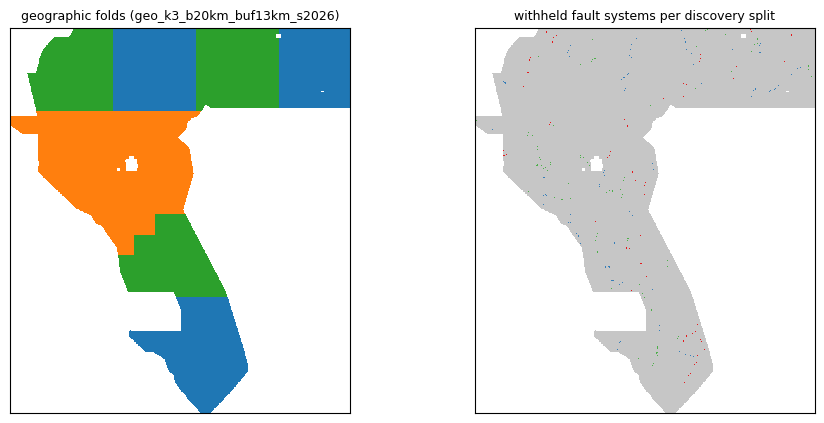

In [10]:
pipe.step('spatial_folds')
pipe.step('discovery_splits')
print(pipe.pc.fold_rel, '|', pipe.pc.discovery_rel)
from gems_bench.pipeline.status import fold_figure, save_fig
fig = fold_figure(pipe.pc)
if fig is not None:
    display(fig); save_fig(pipe.pc, fig, 'validation_design')

## 12. Feature store: create once, reuse

Families: raw 19-channel geophysics · Phase 2 engineered · Phase 1 `eda:*` maps · Phase 4 remote-sensing structural features (those the baselines use, or all) · Phase 5 fault-normal profiles · 1 m DEM aggregates. Only missing features are computed. Each family is pushed to Drive as soon as it exists.

Feature-group prerequisites: only the `eda:*` family needs the Phase-1 EDA rasters. If they are missing, that family is deferred and named in the error, while every other family is still built and kept. This means a G1 LightGBM baseline never waits for the EDA, the advanced feature bank or the DEM pilot. `data/feature_store/pipeline_feature_registry.csv` declares, per feature: name, source, transform, scale, support, CRS / grid, NoData behaviour, standardisation and a spec hash.

In [11]:
pipe.step('feature_store')
reg = pathlib.Path('/content/gems_work/data/feature_store/pipeline_feature_registry.csv')
if reg.exists():
    fr = pd.read_csv(reg)
    display(fr.groupby('family').agg(n=('name', 'size'), cached=('cached', 'sum')))

pipe.step('dem_pilot')                               # only runs when the DEM pilot is enabled

if CONFIG['run_mode'] == 'PREPARE_DATA':
    print('PREPARE_DATA ends here (no model training). Next: set run_mode="BASELINES", train_baselines=["G1"], '
          'and run from section 1. The baseline cells below only report the cached state in this mode.')
    pipe.failure_report()

[features] raw: building 19 feature(s)
  feature raw:mag_anom                                             3.5s  robust-z
  feature raw:rtp                                                  3.6s  robust-z
  feature raw:tmi_hg                                               3.7s  robust-z + signed log
  feature raw:geod_2ndinv                                          3.6s  robust-z
  feature raw:iso_grav_anom_slope                                  3.6s  robust-z
  feature raw:tc                                                   3.6s  robust-z
  feature raw:geod_shearrate                                       3.5s  robust-z
  feature raw:geod_dilaterate                                      3.6s  robust-z
  feature raw:tmi_vg                                               3.6s  robust-z
  feature raw:deq_n100a15                                          3.6s  robust-z + signed log
  feature raw:iso_grav_anom_vg                                     3.6s  robust-z
  feature raw:det_elev           

,n,cached
family,,
phase2,48,48
phase2_eda,5,5
phase4_rs,67,67
raw,19,19


[dem_pilot] DISABLED: DEM pilot disabled (stages.run_dem_pilot and dem.enabled); outputs: missing
[dem_pilot] recovery: enable it in CONFIG to build dem_pilot
PREPARE_DATA ends here (no model training). Next: set run_mode="BASELINES", train_baselines=["G1"], and run from section 1. The baseline cells below only report the cached state in this mode.
[pipeline] no failures


## 13. Baselines: restore or train

G1 terrain LightGBM, G3 engineered LightGBM, RS05 (Phase 4), CNN-A and CNN-B (distance-aware), gated dual encoder, plus the label-free B0 lineament floor. A reported score is not a model: each baseline is `AVAILABLE` only if its finished run folder and maps are found and verified. Otherwise it is `NOT_AVAILABLE`, or it is retrained from the committed configuration snapshot **only when listed in `train_baselines`** and the mode is `BASELINES` or later.

**Next execution target: G1** (`run_mode='BASELINES'`, `train_baselines=['G1']`, CPU). It runs geographic CV, then a full fit per pseudo-discovery split. OOF and discovery maps and `PROVENANCE.json` (fold / split sha256, `historical_equivalence: false`) go to Drive. A regenerated G1 is a new run under the historical recipe. It is not a reproduction of the historical DTI until its metrics have been checked. GPU baselines on a CPU runtime are listed as *not attempted*.

In [12]:
pipe.step('baselines')
display(pipe.baselines())

[baselines] not part of mode PREPARE_DATA: outputs missing - baselines: missing - baseline_status.csv: missing - file not found


,model,kind,gpu,cv_dir,origin,status,discovery,checkpoints,detail
0,B0_lineament,map,False,outputs/benchmark/experiments/b0_lineament_fus...,,NOT_AVAILABLE,n/a,False,no run folder
1,G1,lgbm_p2,False,outputs/benchmark/experiments/lgbm_G1_s2026,,NOT_AVAILABLE,0/3,False,no run folder
2,G3,lgbm_p2,False,outputs/benchmark/experiments/lgbm_G3_s2026,,NOT_AVAILABLE,0/3,False,no run folder
3,RS05_G3_noSS_RS,lgbm_rs,False,outputs/phase4/experiments/p4_RS05_G3_noSS_RS_...,,NOT_AVAILABLE,0/3,False,no run folder
4,CNN_A_dti,cnn3,True,outputs/phase3/experiments/p3_CNN_A_dti_p256_s...,,NOT_AVAILABLE,0/3,False,no run folder
5,DL00_CNN_B_dti,cnn3_p4,True,outputs/phase4/experiments/p4_DL00_CNN_B_dti_p...,,NOT_AVAILABLE,0/3,False,no run folder
6,DL02_CNN_TMGB_dti,cnn3_p4,True,outputs/phase4/experiments/p4_DL02_CNN_TMGB_dt...,,NOT_AVAILABLE,0/3,False,no run folder
7,P4_B_gated,cnn4,True,outputs/phase4/experiments/p4_P4_B_gated_p256_...,,NOT_AVAILABLE,0/3,False,no run folder


## 14–15. Research experiments: PU supervision, geometry-aware decoding, GeoStructureNet, multiscale structure

Each experiment has a hypothesis, a control, a fixed split version, resumable units (3 CV folds + 3 discovery splits), checkpoints synced to Drive at intervals, and the section-17 promotion gate. Order matters: `b0_reference` is the control of the others. GPU only; enable with `run_advanced_models=True`.

In [13]:
display(pipe.experiments())
pipe.step('advanced_models')

,experiment,group,control,resource,hypothesis,promotion,experiment_id,kind,prepare,train,evaluate,export,complete
0,b0_reference,B/C/E control,P4_B_gated,gpu,Re-training the gated dual encoder with the Ph...,section-17 promotion gate (configs/validation/...,b0_reference__d54e938a,cnn5,pending,pending,pending,pending,False
1,b1_bg_weight,B: PU supervision,P5_B0_gated,gpu,Down-weighting unlabeled pixels that carry str...,section-17 promotion gate (configs/validation/...,b1_bg_weight__7755635b,cnn5,pending,pending,pending,pending,False
2,b2_nnpu_p010,B: PU supervision,P5_B0_gated,gpu,nnPU with prior 1 % (central value of the swee...,section-17 promotion gate (configs/validation/...,b2_nnpu_p010__e0173a9a,cnn5,pending,pending,pending,pending,False
3,c1_geometry_heads,C: geometry,P5_B0_gated,gpu,Auxiliary distance-to-fault and axial-orientat...,section-17 promotion gate (configs/validation/...,c1_geometry_heads__9a77180d,cnn5,pending,pending,pending,pending,False
4,e1_gsn_parity,E: GeoStructureNet,P5_B0_gated,gpu,GeoStructureNet in parity configuration (gated...,section-17 promotion gate (configs/validation/...,e1_gsn_parity__b8b8c3db,cnn5,pending,pending,pending,pending,False


[advanced_models] not part of mode PREPARE_DATA: outputs missing - advanced_models: missing - b0_reference__d54e938a: missing - prepare=pending, train=pending, evaluate=pending, export=pending; b1_bg_weight__7755635b: missing - prepare=pending, train=pending, evaluate=pending, export=pending; b2_nnpu_p010__e0173a9a: missing - prepare=pending, train=pending, evaluate=pending, export=pending; c1_geometry_heads__9a77180d: missing - prepare=pending, train=pending, evaluate=pending, export=pending (+1 more)


Report(name='advanced_models', checks=[Check(path='experiments/b0_reference__d54e938a', status='missing', reason='prepare=pending, train=pending, evaluate=pending, export=pending', info={}), Check(path='experiments/b1_bg_weight__7755635b', status='missing', reason='prepare=pending, train=pending, evaluate=pending, export=pending', info={}), Check(path='experiments/b2_nnpu_p010__e0173a9a', status='missing', reason='prepare=pending, train=pending, evaluate=pending, export=pending', info={}), Check(path='experiments/c1_geometry_heads__9a77180d', status='missing', reason='prepare=pending, train=pending, evaluate=pending, export=pending', info={}), Check(path='experiments/e1_gsn_parity__b8b8c3db', status='missing', reason='prepare=pending, train=pending, evaluate=pending, export=pending', info={})], notes=[])

## 16–17. Geographic and pseudo-discovery validation, model comparison and promotion

One protocol for every available model: geographic DTI (cross-fitted area budget) and pseudo-discovery DTI (withheld systems excluded / retained as FP) are reported **separately**; `public_lb` comes only from your manual `reports/leaderboard_log.csv`. Promotion to `promoted` is a manual, evidence-backed registry transition.

In [14]:
pipe.step('discovery_validation')
sb = pathlib.Path('/content/gems_work/reports/pipeline/scoreboard_latest.csv')
if sb.exists():
    b = __import__('pandas').read_csv(sb)
    display(b[[c for c in ('model', 'geo_dti_area', 'geo_fold_min', 'disc_dti_excl', 'disc_dti_retained_fp',
                           'short_recall_w', 'public_lb') if c in b.columns]])
from gems_bench.artifacts import ModelRegistry
display(ModelRegistry(pipe.pc.local / 'model_registry').table())
# Manual promotion (only when the candidate's promotion_decisions say promote=True):
# from gems_bench.experiment.promote import promote
# promote('<model_name>', '<experiment_id>'); pipe.push_all()

[discovery_validation] not part of mode PREPARE_DATA: outputs missing - discovery_validation: missing - models: missing - no model maps available


,name,status,kind,experiment_id,oof,discovery,config_hash,git_commit,geo_dti,disc_dti_excl,disc_dti_retained_fp,protocol_hash,updated,notes


## 18. Ensemble optimisation

Members (≥ 2 with OOF + every discovery map) enter as per-fold rank quantiles; geographic weights are chosen on other folds, discovery weights with each split's withheld systems removed. An ensemble must pass the same gate against its best member.

In [15]:
pipe.step('ensemble')

[ensemble] not part of mode PREPARE_DATA: outputs missing - ensemble: missing - members: missing - only [] have complete maps


Report(name='ensemble', checks=[Check(path='members', status='missing', reason='only [] have complete maps', info={})], notes=[])

## 19–20. Full-area inference and competition GeoTIFF

Uses the registry **champion** (status `promoted`): fold models averaged over the full footprint (chunked, Hann-blended tiles), area-budget export policy, one validated single-band float32 GeoTIFF per known-fault policy in `submissions/` with provenance JSON. **Uploading is manual**; record each upload in `reports/leaderboard_log.csv`.

In [16]:
pipe.step('full_inference')
pipe.step('submission')
import pandas as pd
from gems_bench.evaluation.scoreboard import LEADERBOARD_COLUMNS
log = pipe.pc.local / 'reports' / 'leaderboard_log.csv'
if not log.exists():
    pd.DataFrame(columns=LEADERBOARD_COLUMNS).to_csv(log, index=False)
display(pd.read_csv(log))

[sync in] 0 copied (0.0 MiB), 0 unchanged, 0s: ['submissions', 'model_registry']
[full_inference] not part of mode PREPARE_DATA: outputs missing - full_inference: missing - z_submission__c46ee057:train: missing - pending; full_region.tif: missing - file not found
[sync in] 0 copied (0.0 MiB), 0 unchanged, 0s: ['submissions', 'model_registry']
[submission] not part of mode PREPARE_DATA: outputs missing - submission: missing - z_submission__c46ee057:export: missing - pending


,submitted_at,model,submission_file,known_fault_policy,public_score,notes


## 21. Figures and research reporting

`reports/pipeline/` on Drive: `PIPELINE_REPORT.md`, `stage_status.csv`, `dashboard_summary.csv`, `baseline_status.csv`, `experiment_status.csv`, `scoreboard_latest.csv`, `figures/*.png|svg`. Per-experiment tables and figures stay in `experiments/<id>/`.

[reports] not part of mode PREPARE_DATA: outputs missing - reports: missing - stage_status.csv: missing - file not found


,key,value
0,time,2026-10-22 21:18
1,mode,PREPARE_DATA
2,device,Tesla T4
3,vram_gb,14.6
4,drive,/content/drive/MyDrive/GEMS_2
5,stages_done,6
6,stages_cached,4
7,stages_pending,6
8,stages_failed,0
9,stages_blocked,0


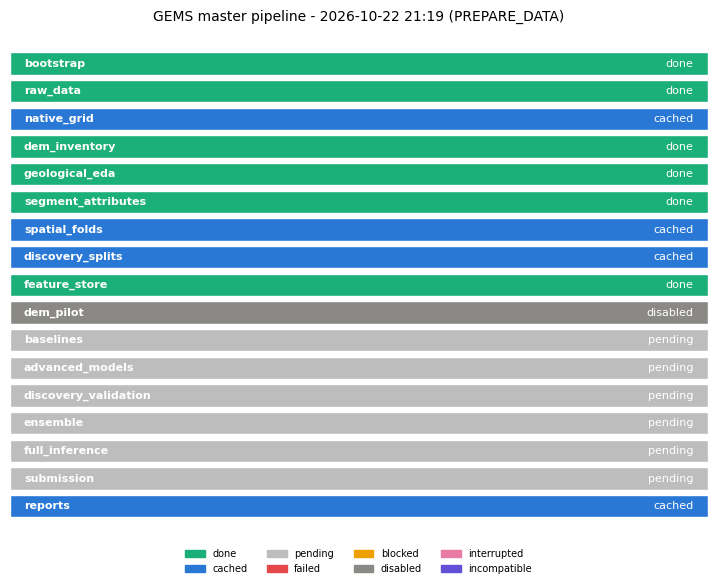

[sync out] 5 copied (0.2 MiB), 2 unchanged, 0s: ['reports/pipeline']


,key,value
0,time,2026-10-22 21:18
1,mode,PREPARE_DATA
2,device,Tesla T4
3,vram_gb,14.6
4,drive,/content/drive/MyDrive/GEMS_2
5,stages_done,6
6,stages_cached,4
7,stages_pending,6
8,stages_failed,0
9,stages_blocked,0


In [17]:
pipe.step('reports')
pipe.dashboard()

## 22. Final artifact and manifest validation

Re-validates every stage's outputs **on Drive** (what survives the session), lists the stage records and the latest events.

In [18]:
pipe.push_all()
final = pipe.plan(mode='FULL_PIPELINE', root='drive')
display(final[['stage', 'outputs', 'planned', 'last_status', 'last_origin', 'last_finished', 'detail']])
display(pipe.status())
display(pipe.events(30))
for s in ('feature_store', 'baselines', 'discovery_validation', 'submission'):
    print(s, '->', pipe.outputs(s)[:3])

[sync out] 9 copied (1.6 MiB), 219 unchanged, 1s: ['environment/pipeline', 'reports', 'environment/pipeline/config_snapshot.json', 'reports/pipeline/environment_report.csv', 'data/raw/acquisition_manifest.json', 'reports/pipeline/raw_data_acquisition.csv', 'environment/pipeline/native_grid.json', 'data/raw/dem_1m/inventory', 'data/raw/dem_1m/tnm_urls.json', 'outputs/eda/manifest.json', 'outputs/eda/datasets', 'outputs/eda/features/lineament_maps.tif', 'outputs/eda/features/crossmodal_orientation.tif', 'outputs/eda/REBUILD_PROVENANCE.json', 'outputs/eda/INSTALL_STATE.json', 'outputs/eda_rebuild', 'outputs/benchmark/datasets/native_segment_ids.tif', 'outputs/benchmark/datasets/segment_attributes.parquet', 'outputs/benchmark/datasets/native_segments_provenance.json', 'outputs/benchmark/folds/geo_k3_b20km_buf13km_s2026', 'outputs/benchmark/folds/discovery_d3_link1km_s2026', 'outputs/benchmark/cache/features/raw_mag_anom.npy', 'outputs/benchmark/cache/features/raw_rtp.npy', 'outputs/benchma

,stage,outputs,planned,last_status,last_origin,last_finished,detail
0,bootstrap,ok,SKIP_CACHED,done,built,2026-10-22T20:45:07,bootstrap: ok (3 checks)
1,raw_data,ok,SKIP_CACHED,done,built,2026-10-22T20:45:28,raw_data: ok (3 checks)
2,native_grid,ok,SKIP_CACHED,done,built,2026-10-22T13:40:01,native_grid: ok (1 checks)
3,dem_inventory,ok,SKIP_CACHED,done,built,2026-10-22T20:46:34,dem_inventory: ok (2 checks)
4,geological_eda,ok,SKIP_CACHED,done,built,2026-10-22T20:50:36,eda_minimal: ok (7 checks)
5,segment_attributes,ok,SKIP_CACHED,done,built,2026-10-22T20:50:38,native_segments: ok (2 checks)
6,spatial_folds,ok,SKIP_CACHED,done,adopted_existing,2026-10-22T13:40:02,folds:geo_k3_b20km_buf13km_s2026: ok (3 checks)
7,discovery_splits,ok,SKIP_CACHED,done,adopted_existing,2026-10-22T13:40:03,discovery:discovery_d3_link1km_s2026: ok (3 ch...
8,feature_store,ok,SKIP_CACHED,done,built,2026-10-22T21:18:58,feature_store: ok (139 checks)
9,dem_pilot,missing,DISABLED (DEM pilot disabled (stages.run_dem_p...,,,,dem_pilot: missing - f1_dem_pilot__888c6e12:pr...


,stage,state,title,resource,origin,last_finished,attempts,reason,recovery,outputs
0,bootstrap,done,"Environment, Drive, workspace folders",light,built,2026-10-22T20:45:07,2,bootstrap: ok (3 checks),,"environment/pipeline/config_snapshot.json, rep..."
1,raw_data,done,"Competition files: locate, validate, download ...",network,built,2026-10-22T20:45:28,2,raw_data: ok (3 checks),,"data/raw/acquisition_manifest.json, reports/pi..."
2,native_grid,cached,"Native 100 m grid, labels, template checks",cpu,built,2026-10-22T13:40:01,1,native_grid: ok (1 checks),,"environment/pipeline/native_grid.json, reports..."
3,dem_inventory,done,USGS 1 m DEM inventory (metadata only),light,built,2026-10-22T20:46:34,1,dem_inventory: ok (2 checks),,"data/raw/dem_1m/inventory, data/raw/dem_1m/tnm..."
4,geological_eda,done,Phase-1 EDA dependency repair (minimal rebuild),cpu-heavy,built,2026-10-22T20:50:36,2,eda_minimal: ok (7 checks),,"outputs/eda/manifest.json, outputs/eda/datasets"
5,segment_attributes,done,Native-grid segment ids + attributes,cpu,built,2026-10-22T20:50:38,1,native_segments: ok (2 checks),,outputs/benchmark/datasets/native_segment_ids....
6,spatial_folds,cached,Geographic folds (Phase-2 protocol),cpu,adopted_existing,2026-10-22T13:40:02,1,folds:geo_k3_b20km_buf13km_s2026: ok (3 checks),,outputs/benchmark/folds/geo_k3_b20km_buf13km_s...
7,discovery_splits,cached,Pseudo-discovery fault-system splits,cpu,adopted_existing,2026-10-22T13:40:03,1,discovery:discovery_d3_link1km_s2026: ok (3 ch...,,outputs/benchmark/folds/discovery_d3_link1km_s...
8,feature_store,done,"Feature store: compute once, reuse",cpu-heavy,built,2026-10-22T21:18:58,1,feature_store: ok (139 checks),,outputs/benchmark/cache/features/raw_mag_anom....
9,dem_pilot,disabled,"1 m DEM pilot: selection, download, morphology...",network-heavy,,,0,DEM pilot disabled (stages.run_dem_pilot and d...,enable it in CONFIG to build dem_pilot,"experiments/f1_dem_pilot__888c6e12, data/proce..."


,time,stage,event,decision,validation,seconds,reason
0,2026-10-22T13:38:12,bootstrap,start,RUN,ok,NaN,NaN
1,2026-10-22T13:38:18,bootstrap,done,NaN,NaN,6.7,NaN
2,2026-10-22T13:38:24,raw_data,start,BUILD,missing,NaN,NaN
3,2026-10-22T13:38:36,raw_data,done,NaN,NaN,12.3,NaN
4,2026-10-22T13:38:36,native_grid,start,BUILD,missing,NaN,NaN
5,2026-10-22T13:40:01,native_grid,done,NaN,NaN,84.2,NaN
6,2026-10-22T13:40:01,geological_eda,start,BUILD,missing,NaN,NaN
7,2026-10-22T13:40:01,geological_eda,failed,NaN,NaN,NaN,NameError: name 'version' is not defined
8,2026-10-22T13:40:06,reports,start,RUN,missing,NaN,NaN
9,2026-10-22T13:40:09,reports,done,NaN,NaN,2.5,NaN


feature_store -> ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_mag_anom.npy', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_rtp.npy', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/cache/features/raw_tmi_hg.npy']
baselines -> ['/content/drive/MyDrive/GEMS_2/outputs/benchmark/experiments/b0_lineament_fused_s2026', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/experiments/lgbm_G1_s2026', '/content/drive/MyDrive/GEMS_2/outputs/benchmark/experiments/disc0_lgbm_G1_s2026']
discovery_validation -> []
submission -> ['/content/drive/MyDrive/GEMS_2/experiments/z_submission__c46ee057', '/content/drive/MyDrive/GEMS_2/submissions', '/content/drive/MyDrive/GEMS_2/model_registry']


## 23. Resume, inspect a failure, update the code

After a disconnect or in a new session: **run sections 1–4 again, then the same cells (or `pipe.run()`)**.

* Finished stages are `SKIP_CACHED` (validated on Drive, staged back to `/content/gems_work` only when needed). Raw files and folds are never downloaded or regenerated again.
* **A stage failed?** `pipe.explain('<stage>')` prints the error, `file:line`, the recovery action and the traceback, also for a failure recorded in an earlier session. `pipe.failure_report()` lists each root failure and the stages it blocks.
* **After a fix is pushed to GitHub:** *Runtime → Restart session*, then run from section 1. The installation cell fast-forwards `ref` (or checks out the pinned SHA) and prints the commit. Completed stages are skipped; the failed stage resumes.
* Interrupted feature builds continue with the missing features. Interrupted experiments continue at the next CV fold / discovery split and resume training from the last checkpoint pushed to Drive (`ckpt_sync_min`).
* To change a protocol (folds, features, experiment settings), edit the configuration. A new versioned folder / experiment id is created, and earlier results are kept.
* On short sessions set `max_stage_minutes` (e.g. 200): training stops cleanly at an epoch boundary and resumes next time.

The original notebooks `00`–`07` remain as focused research entry points; this notebook is the recommended start.